In [1]:
import pandas as pd
import numpy as np

from sklearn.model_selection import (
    train_test_split,
    GridSearchCV,
    cross_val_score,
    cross_val_predict
)

from sklearn.preprocessing import StandardScaler

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

from sklearn.pipeline import Pipeline

from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
df = pd.read_csv("appointments_clean.csv")

print("Dataset shape:", df.shape)

display(df.head())

Dataset shape: (990, 16)


,appointment_id,patient_id,clinic_id,booked_on,appt_date,age,gender,distance_km,fee_inr,booking_channel,visit_type,reminder_sent,prior_no_shows,status,lead_days,no_show
0,A0001,P509,C05,2025-01-24,2025-01-25,60.0,F,18.0,850,Phone,Consultation,Yes,1,No-Show,1,1
1,A0002,P046,C07,2025-05-27,2025-06-06,39.0,M,12.5,350,Walk-In,Follow-up,No,2,Attended,10,0
2,A0003,P009,C02,2025-03-24,2025-03-30,63.0,F,4.1,850,Walk-In,Consultation,No,0,Attended,6,0
3,A0004,P482,C01,2025-04-18,2025-04-22,52.0,F,7.5,750,App,Consultation,Yes,0,Attended,4,0
4,A0005,P251,C01,2024-11-23,2025-01-02,64.0,F,19.0,700,Phone,Consultation,No,0,No-Show,40,1


In [3]:
features = [
    "age",
    "distance_km",
    "fee_inr",
    "lead_days",
    "prior_no_shows",
    "reminder_sent",
    "booking_channel",
    "visit_type"
]

X = df[features].copy()

y = df["no_show"]

X["reminder_sent"] = X["reminder_sent"].map({
    "Yes": 1,
    "No": 0
})

X = pd.get_dummies(
    X,
    columns=["booking_channel", "visit_type"],
    dtype=int
)

print("Feature shape:", X.shape)
print("Target shape:", y.shape)

display(X.head())

Feature shape: (990, 11)
Target shape: (990,)


,age,distance_km,fee_inr,lead_days,prior_no_shows,reminder_sent,booking_channel_App,booking_channel_Phone,booking_channel_Walk-In,visit_type_Consultation,visit_type_Follow-up
0,60.0,18.0,850,1,1,1,0,1,0,1,0
1,39.0,12.5,350,10,2,0,0,0,1,0,1
2,63.0,4.1,850,6,0,0,0,0,1,1,0
3,52.0,7.5,750,4,0,1,1,0,0,1,0
4,64.0,19.0,700,40,0,0,0,1,0,1,0


In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))
print("No-shows in test set:", y_test.sum())
print("Attended in test set:", (y_test == 0).sum())

Training records: 792
Testing records: 198
No-shows in test set: 49
Attended in test set: 149


In [5]:
baseline_predictions = np.zeros(len(y_test))

baseline_accuracy = accuracy_score(
    y_test,
    baseline_predictions
)

print("Baseline Accuracy:", round(baseline_accuracy, 4))
print("Baseline Percentage:", round(baseline_accuracy * 100, 2))

Baseline Accuracy: 0.7525
Baseline Percentage: 75.25


In [6]:
scaler = StandardScaler()

X_train_s = scaler.fit_transform(X_train)

X_test_s = scaler.transform(X_test)

print("Feature scaling completed successfully!")

Feature scaling completed successfully!


In [7]:
model = LogisticRegression(max_iter=1000)

model.fit(X_train_s, y_train)

y_pred = model.predict(X_test_s)

y_prob = model.predict_proba(X_test_s)[:, 1]

print("Logistic Regression trained successfully!")

Logistic Regression trained successfully!


In [8]:
print("Accuracy:", accuracy_score(y_test, y_pred))

print("Precision:", precision_score(y_test, y_pred))

print("Recall:", recall_score(y_test, y_pred))

print("F1 Score:", f1_score(y_test, y_pred))

print("ROC-AUC:", roc_auc_score(y_test, y_prob))

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))

Accuracy: 0.7878787878787878
Precision: 0.6296296296296297
Recall: 0.3469387755102041
F1 Score: 0.4473684210526316
ROC-AUC: 0.788933022873579
Confusion Matrix:
[[139  10]
 [ 32  17]]


In [9]:
coefficients = pd.DataFrame({
    "Feature": X.columns,
    "Coefficient": model.coef_[0]
})

display(
    coefficients.sort_values(
        "Coefficient",
        ascending=False
    )
)

,Feature,Coefficient
4,prior_no_shows,0.649612
3,lead_days,0.614471
2,fee_inr,0.452761
1,distance_km,0.253448
7,booking_channel_Phone,0.215881
9,visit_type_Consultation,0.015658
10,visit_type_Follow-up,-0.015658
6,booking_channel_App,-0.046804
8,booking_channel_Walk-In,-0.186364
0,age,-0.253880


In [10]:
index = X.columns.get_loc("reminder_sent")

coefficient = model.coef_[0][index]

standard_deviation = scaler.scale_[index]

scaled_odds_ratio = np.exp(coefficient)

actual_odds_ratio = np.exp(
    coefficient / standard_deviation
)

print("Reminder coefficient:", coefficient)

print("Scaled odds ratio:", scaled_odds_ratio)

print("Actual odds ratio:", actual_odds_ratio)

print(
    "Percentage reduction in odds:",
    (1 - actual_odds_ratio) * 100
)

Reminder coefficient: -0.5806686033659922
Scaled odds ratio: 0.559524141750829
Actual odds ratio: 0.3093980903124433
Percentage reduction in odds: 69.06019096875566


In [11]:
tree_full = DecisionTreeClassifier(random_state=42)

tree_full.fit(X_train, y_train)

print("Training Accuracy:",
      tree_full.score(X_train, y_train))

print("Testing Accuracy:",
      tree_full.score(X_test, y_test))

print("Tree Depth:",
      tree_full.get_depth())

Training Accuracy: 1.0
Testing Accuracy: 0.6717171717171717
Tree Depth: 15


In [12]:
tree3 = DecisionTreeClassifier(
    max_depth=3,
    random_state=42
)

tree3.fit(X_train, y_train)

print("Training Accuracy:",
      tree3.score(X_train, y_train))

print("Testing Accuracy:",
      tree3.score(X_test, y_test))

print("Tree Depth:",
      tree3.get_depth())

Training Accuracy: 0.821969696969697
Testing Accuracy: 0.7777777777777778
Tree Depth: 3


In [13]:
rf = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

rf.fit(X_train, y_train)

rf_pred = rf.predict(X_test)

rf_prob = rf.predict_proba(X_test)[:, 1]

print("Random Forest trained successfully!")

Random Forest trained successfully!


In [14]:
print("Training Accuracy:",
      rf.score(X_train, y_train))

print("Testing Accuracy:",
      accuracy_score(y_test, rf_pred))

print("Precision:",
      precision_score(y_test, rf_pred))

print("Recall:",
      recall_score(y_test, rf_pred))

print("F1 Score:",
      f1_score(y_test, rf_pred))

print("ROC-AUC:",
      roc_auc_score(y_test, rf_prob))

Training Accuracy: 1.0
Testing Accuracy: 0.7474747474747475
Precision: 0.4838709677419355
Recall: 0.30612244897959184
F1 Score: 0.375
ROC-AUC: 0.7057252431173813


In [15]:
importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": rf.feature_importances_
})

importance = importance.sort_values(
    "Importance",
    ascending=False
)

display(importance.head(3))

,Feature,Importance
3,lead_days,0.219905
0,age,0.196788
1,distance_km,0.194739


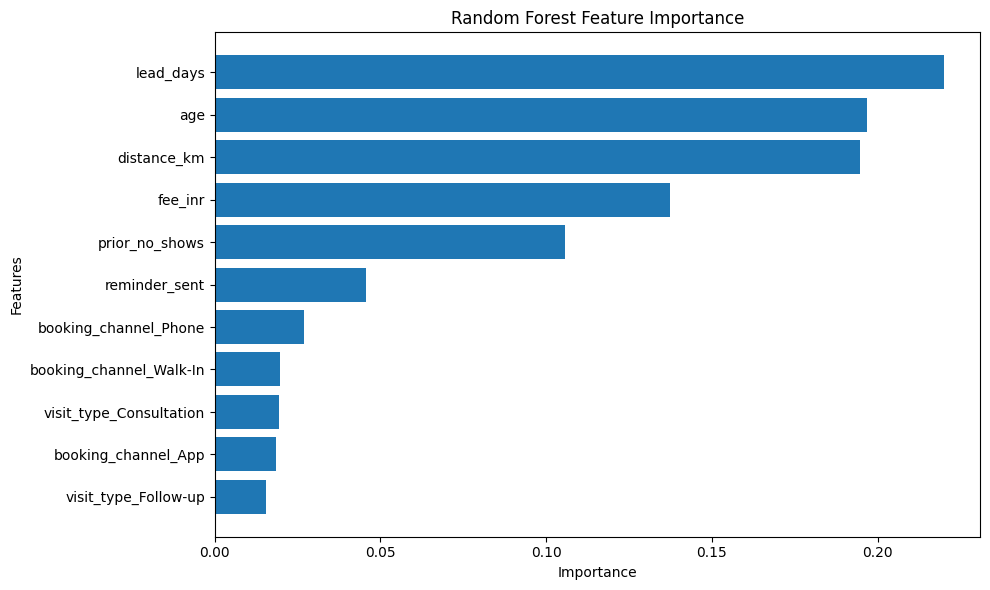

In [16]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

plt.barh(
    importance["Feature"],
    importance["Importance"]
)

plt.gca().invert_yaxis()

plt.xlabel("Importance")
plt.ylabel("Features")
plt.title("Random Forest Feature Importance")

plt.tight_layout()
plt.show()

In [17]:
lr_pred = model.predict(X_test_s)
lr_prob = model.predict_proba(X_test_s)[:, 1]

tree_pred = tree3.predict(X_test)
tree_prob = tree3.predict_proba(X_test)[:, 1]

comparison = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Decision Tree (Depth 3)",
        "Random Forest"
    ],

    "Accuracy": [
        accuracy_score(y_test, lr_pred),
        accuracy_score(y_test, tree_pred),
        accuracy_score(y_test, rf_pred)
    ],

    "Recall": [
        recall_score(y_test, lr_pred),
        recall_score(y_test, tree_pred),
        recall_score(y_test, rf_pred)
    ],

    "ROC-AUC": [
        roc_auc_score(y_test, lr_prob),
        roc_auc_score(y_test, tree_prob),
        roc_auc_score(y_test, rf_prob)
    ]
})

display(comparison.round(4))

,Model,Accuracy,Recall,ROC-AUC
0,Logistic Regression,0.7879,0.3469,0.7889
1,Decision Tree (Depth 3),0.7778,0.2245,0.6997
2,Random Forest,0.7475,0.3061,0.7057


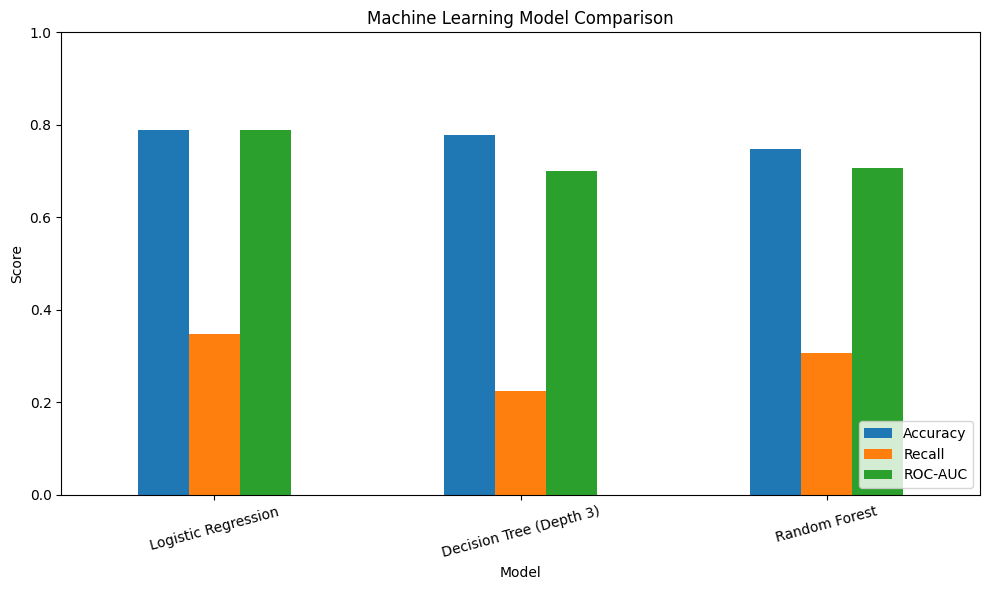

In [18]:
comparison.set_index("Model").plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title("Machine Learning Model Comparison")
plt.ylabel("Score")
plt.xlabel("Model")
plt.ylim(0, 1)
plt.xticks(rotation=15)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

In [19]:
param_grid = {
    "n_estimators": [100, 200],
    "max_depth": [3, 5, 8]
}

grid_search = GridSearchCV(
    RandomForestClassifier(random_state=42),
    param_grid,
    cv=5,
    scoring="roc_auc"
)

grid_search.fit(X_train, y_train)

print("Best Parameters:", grid_search.best_params_)

print("Best CV ROC-AUC:", grid_search.best_score_)

Best Parameters: {'max_depth': 3, 'n_estimators': 200}
Best CV ROC-AUC: 0.7673242251739405


In [20]:
tuned_rf = grid_search.best_estimator_

print("Tuned Random Forest is ready!")

Tuned Random Forest is ready!


In [21]:
lr_pipe = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(max_iter=1000))
])

print("Logistic Regression pipeline created!")

Logistic Regression pipeline created!


In [22]:
lr_cv = cross_val_score(
    lr_pipe,
    X_train,
    y_train,
    cv=5,
    scoring="roc_auc"
).mean()

tree_cv = cross_val_score(
    tree3,
    X_train,
    y_train,
    cv=5,
    scoring="roc_auc"
).mean()

rf_cv = cross_val_score(
    rf,
    X_train,
    y_train,
    cv=5,
    scoring="roc_auc"
).mean()

tuned_rf_cv = grid_search.best_score_

cv_results = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Decision Tree (Depth 3)",
        "Random Forest",
        "Tuned Random Forest"
    ],
    "CV ROC-AUC": [
        lr_cv,
        tree_cv,
        rf_cv,
        tuned_rf_cv
    ]
})

display(
    cv_results.sort_values(
        "CV ROC-AUC",
        ascending=False
    )
)

,Model,CV ROC-AUC
0,Logistic Regression,0.773714
3,Tuned Random Forest,0.767324
2,Random Forest,0.746602
1,Decision Tree (Depth 3),0.678449


In [23]:
models = {
    "Logistic Regression": lr_pipe,
    "Decision Tree (Depth 3)": tree3,
    "Random Forest": rf,
    "Tuned Random Forest": tuned_rf
}

cv_scores = {
    "Logistic Regression": lr_cv,
    "Decision Tree (Depth 3)": tree_cv,
    "Random Forest": rf_cv,
    "Tuned Random Forest": tuned_rf_cv
}

best_model_name = max(
    cv_scores,
    key=cv_scores.get
)

best_model = models[best_model_name]

print("Best Model:", best_model_name)

print("Best CV ROC-AUC:",
      cv_scores[best_model_name])

Best Model: Logistic Regression
Best CV ROC-AUC: 0.7737139899948249


In [24]:
oof_probs = cross_val_predict(
    best_model,
    X_train,
    y_train,
    cv=5,
    method="predict_proba"
)[:, 1]

print("Out-of-fold probabilities generated!")

print("Total probabilities:", len(oof_probs))

Out-of-fold probabilities generated!
Total probabilities: 792


In [25]:
threshold_results = []

for threshold in [0.5, 0.35]:

    predictions = (
        oof_probs >= threshold
    ).astype(int)

    threshold_results.append({
        "Threshold": threshold,

        "Precision": precision_score(
            y_train, predictions,
            zero_division=0
        ),

        "Recall": recall_score(
            y_train, predictions
        ),

        "F1 Score": f1_score(
            y_train, predictions
        ),

        "Number Flagged": predictions.sum()
    })

threshold_df = pd.DataFrame(threshold_results)

display(threshold_df.round(4))

,Threshold,Precision,Recall,F1 Score,Number Flagged
0,0.50,0.5753,0.2485,0.3471,73
1,0.35,0.5130,0.4675,0.4892,154


In [26]:
best_threshold = float(
    threshold_df.loc[
        threshold_df["F1 Score"].idxmax(),
        "Threshold"
    ]
)

print("Best Threshold:", best_threshold)

Best Threshold: 0.35


The threshold of 0.35 was selected because it achieved a higher F1 score and improved recall from approximately 25% to 47% on training-set cross-validation. Recall is important because failing to identify a risky appointment can result in an empty doctor slot, whereas an additional follow-up call costs relatively little.

In [27]:
best_model.fit(X_train, y_train)

final_probs = best_model.predict_proba(
    X_test
)[:, 1]

final_predictions = (
    final_probs >= best_threshold
).astype(int)

print("Final model trained successfully!")

Final model trained successfully!


In [28]:
print("Final Model:", best_model_name)

print("Selected Threshold:", best_threshold)

print("Accuracy:",
      accuracy_score(y_test, final_predictions))

print("Precision:",
      precision_score(
          y_test, final_predictions,
          zero_division=0
      ))

print("Recall:",
      recall_score(y_test, final_predictions))

print("F1 Score:",
      f1_score(y_test, final_predictions))

print("ROC-AUC:",
      roc_auc_score(y_test, final_probs))

print("Number Flagged:",
      final_predictions.sum())

print("Confusion Matrix:")
print(confusion_matrix(y_test, final_predictions))

Final Model: Logistic Regression
Selected Threshold: 0.35
Accuracy: 0.7878787878787878
Precision: 0.5714285714285714
Recall: 0.5714285714285714
F1 Score: 0.5714285714285714
ROC-AUC: 0.788933022873579
Number Flagged: 49
Confusion Matrix:
[[128  21]
 [ 21  28]]


In [29]:
risk_scores = pd.DataFrame({
    "appointment_id": df.loc[
        X_test.index, "appointment_id"
    ].to_numpy(),

    "no_show": y_test.to_numpy(),

    "risk_prob": final_probs,

    "flag": final_predictions
})

risk_scores.to_csv(
    "test_risk_scores.csv",
    index=False
)

print("test_risk_scores.csv created successfully!")

display(risk_scores.head(10))

test_risk_scores.csv created successfully!


,appointment_id,no_show,risk_prob,flag
0,A0217,0,0.021565,0
1,A0336,0,0.150917,0
2,A0508,0,0.518692,1
3,A0314,0,0.191300,0
4,A0089,0,0.167718,0
5,A0543,1,0.319977,0
6,A0284,0,0.338448,0
7,A0109,1,0.367038,1
8,A0060,0,0.104999,0
9,A0513,0,0.173261,0


In [30]:
print("Total rows:", len(risk_scores))

print("Total columns:", len(risk_scores.columns))

print("Missing values:",
      risk_scores.isna().sum().sum())

print("Flagged appointments:",
      risk_scores["flag"].sum())

print("Unique appointment IDs:",
      risk_scores["appointment_id"].nunique())

assert len(risk_scores) == 198

assert risk_scores["flag"].sum() == final_predictions.sum()

Total rows: 198
Total columns: 4
Missing values: 0
Flagged appointments: 49
Unique appointment IDs: 198


The final model identifies high-risk appointments before the scheduled visit. Logistic Regression is expected to achieve a ROC-AUC of approximately 0.79 on the test data. With a threshold of 0.35, the model flags approximately 49 out of 198 appointments for follow-up. In practice, CareLoop should choose its threshold based on the number of follow-up calls the front desk can make and the cost of an empty doctor slot.

In [31]:
from google.colab import files

files.download("test_risk_scores.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>